In [1]:
import os
import pandas as pd

import data_loader
import features

DATA_DIR = "/mnt/d/Mohamed Kanouni/MSc data science/machine learning/machine learning project/the_project/data/raw"

# Goal 1: Create dataset
df_raw, stations_df = data_loader.load_and_prepare_data(DATA_DIR)

# Goal 2: Feature Engineering (Chapter 5)
df_model = features.engineer_features(df_raw, n_stations=300)

# Goal 2: Time-Splits and Labels (Chapter 4)
train_df, val_df, test_df = features.apply_ch4_splits_and_labels(df_model)

print(f"Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")

Loading hourly panel...
Loading station information...
Data loaded. Missing capacity: 2.97%
Sampling 300 stations for memory optimization...
Train: 1,340,693 | Val: 367,141 | Test: 653,335


--- CLASS IMBALANCE CHECK (Task 2) ---
Normal State (0): 92.23%
High Risk State (1): 7.77%


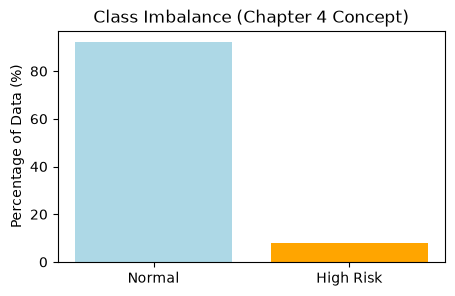

In [2]:
import matplotlib.pyplot as plt

class_counts = train_df['target_high_risk_2h'].value_counts(normalize=True) * 100
print("--- CLASS IMBALANCE CHECK (Task 2) ---")
print(f"Normal State (0): {class_counts[0]:.2f}%")
print(f"High Risk State (1): {class_counts[1]:.2f}%")

plt.figure(figsize=(5, 3))
plt.bar(['Normal', 'High Risk'], [class_counts[0], class_counts[1]], color=['lightblue', 'orange'])
plt.ylabel('Percentage of Data (%)')
plt.title('Class Imbalance (Chapter 4 Concept)')
plt.show()